# L11 — Stereo Vision: Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L11-Stereo/L11_Stereo.ipynb)

This notebook accompanies **Lecture 11**. On Monday (L10) we warped 1958 frame 19 onto frame 20
with a homography and found ±3 px of motion left over, almost all along $x$. A homography is
exact only for a plane, so that leftover is **parallax**: the signal of height. Today we
explain why it runs along $x$, and turn it into **depth**.

Two views of the same point give two rays; where they meet is the point. Everything today
follows from that: the **epipolar constraint** (a match must lie on a line), the
**fundamental** and **essential** matrices that encode it, **rectification** (make those lines
horizontal) and **dense disparity** (search along each row).

As in L10 we need a known answer, so most of the notebook uses a **simulated drone stereo pair**
over the 2020 orthophoto: woodlots, a hill and three barns with known heights. Section 11 goes
back to the real 1958 pair.

| Section | Topic |
|---------|-------|
| 0 | Get the imagery |
| 1 | The running example: a stereo drone pair with ground truth |
| 2 | Depth from disparity: $Z = fB/d$ |
| 3 | Epipolar geometry: the essential and fundamental matrices |
| 4 | Estimating $F$ from matches (eight points, RANSAC), and why not a homography |
| 5 | From $E$ to camera pose to 3-D points |
| 6 | Rectification |
| 7 | Dense matching by hand: the cost volume |
| 8 | OpenCV: StereoBM and semi-global matching |
| 9 | Left–right check and sub-pixel disparity |
| 10 | From disparity to heights |
| 11 | Real data: the 1958 pair |
| 12 | Pitfalls |
| 13 | Make your own magic eye → moved to `L11_MagicEye.ipynb` |

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
cv2.setRNGSeed(0)                         # RANSAC inside OpenCV: same answer every run
print(f"OpenCV {cv2.__version__}, NumPy {np.__version__}")

OpenCV 5.0.0, NumPy 2.5.3


---
## 0 · Get the imagery

**AL5** (the 1958 frames from AL5, L8–L10) and the **2020 colour orthophoto** from L2 and L10.
Safe to re-run.

In [3]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

def fetch_file(name):
    if os.path.exists(name):
        print(f"{name}: already present"); return
    urllib.request.urlretrieve(BASE + name, name)
    print(f"{name}: downloaded")

fetch_zip("AL5.zip", ["frames/16046-19.jpg", "frames/16046-20.jpg"])
fetch_file("eastern_pei_aerial_2020.png")

AL5.zip: already present
eastern_pei_aerial_2020.png: already present


---
## 1 · The running example: a stereo drone pair with ground truth

We build a small 3-D world on top of the orthophoto and photograph it with a pinhole camera.

* **World coordinates** in metres: $X$ east, $Y$ south, $Z$ **down** (so a point $h$ metres
  above the datum has $Z = -h$). With $Z$ down, a camera looking straight down has rotation
  $R = I$ — convenient. We *treat* one orthophoto pixel as 0.5 m.
* **The scene**: a gentle slope and a 20 m hill; woodlots (outlined by hand on the
  orthophoto) with a 13–21 m canopy; three 8–12 m barns with different roofs — one plain
  white, one with ribbed metal, one with ordinary texture. (They are boxes. Like L10's car,
  they are clearly not real barns, but they have the geometry of one.)
* **The cameras**: focal length $f = 500$ px, 640 × 480, flying height 250 m, so one image
  pixel covers 0.5 m on the ground. The **right** camera is $B = 40$ m east of the left one —
  same height, same orientation. That is the textbook stereo rig.

`render(K, R, C)` casts a ray through every pixel and walks down it until it hits the height
field. It returns the image (with σ = 1.5 noise), the **true depth** of every pixel and the
3-D point it sees. (You don't need to follow the ray-marching code; it plays the role of the
real world.)

In [4]:
ORTHO = cv2.cvtColor(cv2.imread("eastern_pei_aerial_2020.png"), cv2.COLOR_BGR2GRAY).astype(np.float32)
OX, OY, GSD = 240, 460, 0.5                  # world (0, 0) is ortho pixel (240, 460); 1 ortho px = 0.5 m
W, H = 640, 480

def to_ortho(X, Y):
    return (OX + X / GSD).astype(np.float32), (OY + Y / GSD).astype(np.float32)

oh, ow = ORTHO.shape
YO, XO = np.mgrid[0:oh, 0:ow].astype(np.float32)
Xm, Ym = (XO - OX) * GSD, (YO - OY) * GSD                         # metres
GROUND = 6 * (1 - Ym / 240) + 20 * np.exp(-((Xm - 230)**2 + (Ym - 85)**2) / (2 * 55**2))   # slope + hill

WOODS = [[(0, 0), (135, 0), (135, 112), (40, 115), (35, 320), (0, 330)],         # outlined by hand
         [(138, 0), (160, 0), (160, 232), (150, 325), (138, 325)],              # (ortho pixels,
         [(400, 0), (640, 0), (640, 330), (400, 312), (340, 305), (340, 100), (400, 100)],   # from the
         [(165, 238), (330, 232), (330, 305), (165, 318)],                       #  world origin)
         [(0, 365), (140, 345), (140, 480), (0, 480)],
         [(155, 343), (360, 328), (360, 480), (155, 480)],
         [(470, 340), (640, 350), (640, 480), (560, 480), (560, 420), (470, 420)]]
mask = np.zeros((oh, ow), np.uint8)
for poly in WOODS:
    cv2.fillPoly(mask, [np.int32([(x + OX, y + OY) for x, y in poly])], 1)
rng = np.random.default_rng(11)
def smooth_noise(sigma):
    z = cv2.GaussianBlur(rng.normal(0, 1, (oh, ow)).astype(np.float32), (0, 0), sigma)
    return z / z.std()
edge = (cv2.GaussianBlur(mask.astype(np.float32), (0, 0), 6) + 0.18 * smooth_noise(4)) > 0.5   # ragged edges
CANOPY = cv2.GaussianBlur(edge.astype(np.float32), (0, 0), 1.2) * (17 + 2 * smooth_noise(4))
HEIGHT = GROUND + CANOPY
TEX = ORTHO.copy()

BARNS = {"white roof":    (60, 160, 40, 24, 10.0),        # x, y (ortho px from origin), w, h, height (m)
         "ribbed roof":   (200, 90, 50, 30, 8.0),
         "textured roof": (385, 395, 40, 30, 12.0)}
for name, (x, y, w, h, ht) in BARNS.items():
    sl = (slice(OY + y, OY + y + h), slice(OX + x, OX + x + w))
    HEIGHT[sl] = GROUND[sl].max() + ht
    if name == "white roof":
        TEX[sl] = 205                                           # no texture at all
    elif name == "ribbed roof":
        TEX[sl] = np.where(np.sin(2 * np.pi * np.arange(w) / 8) > 0, 215, 150)[None, :]   # 4 m ribs

gy, gx = np.gradient(cv2.GaussianBlur(HEIGHT, (0, 0), 2.0), GSD)   # sun from the south-west, 45° up
nrm = np.dstack([-gx, -gy, np.ones_like(gx)]); nrm /= np.linalg.norm(nrm, axis=2, keepdims=True)
sun = np.array([-0.5, 0.5, 0.707]); sun /= np.linalg.norm(sun)
ALBEDO = (TEX * np.clip(0.55 + 0.45 * (nrm @ sun) / sun[2], 0.35, 1.1)).astype(np.float32)
scene = (Xm >= 0) & (Xm < 320) & (Ym >= 0) & (Ym < 240)
print(f"in the 320 × 240 m scene: ground {GROUND[scene].min():.0f}..{GROUND[scene].max():.0f} m, "
      f"highest point {HEIGHT[scene].max():.0f} m")

in the 320 × 240 m scene: ground 0..24 m, highest point 45 m


In [5]:
def render(K, R, C, rng=None, step=0.25):
    # Ray-cast the height field. Camera: x_cam = R (X - C), pixel = K x_cam / z.
    v, u = np.mgrid[0:H, 0:W].astype(np.float64)
    d = (R.T @ (np.linalg.inv(K) @ np.stack([u.ravel(), v.ravel(), np.ones(u.size)]))).T
    hitZ, prev = np.full(u.size, np.nan), None
    for z in np.arange(-HEIGHT.max() - 1, 0.5 + step, step):          # walk down, step metres
        s = (z - C[2]) / d[:, 2]
        mx, my = to_ortho(C[0] + s * d[:, 0], C[1] + s * d[:, 1])
        f = cv2.remap(HEIGHT, mx.reshape(H, W), my.reshape(H, W), cv2.INTER_LINEAR).ravel() + z
        new = np.isnan(hitZ) & (f >= 0)                                 # first step below the surface
        hitZ[new] = z if prev is None else z - step * f[new] / (f[new] - prev[new] + 1e-12)
        prev = f
    P = C + ((hitZ - C[2]) / d[:, 2])[:, None] * d                       # 3-D point seen by each pixel
    mx, my = to_ortho(P[:, 0], P[:, 1])
    img = cv2.remap(ALBEDO, mx.reshape(H, W), my.reshape(H, W), cv2.INTER_LINEAR)
    depth = (R @ (P - C).T)[2].reshape(H, W)
    if rng is not None:
        img = img + rng.normal(0, 1.5, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8), depth, P.reshape(H, W, 3)

F_PX, HF, B = 500.0, 250.0, 40.0                     # focal length (px), flying height (m), baseline (m)
K = np.array([[F_PX, 0, W / 2], [0, F_PX, H / 2], [0, 0, 1]])
C_L = np.array([140.0, 120.0, -HF]); C_R = C_L + [B, 0, 0]

rng = np.random.default_rng(1)
t0 = time.perf_counter()
L, ZL, PL = render(K, np.eye(3), C_L, rng)
R, ZR, PR = render(K, np.eye(3), C_R, rng)
D_TRUE = F_PX * B / ZL                               # true disparity of every left pixel (section 2)
HGT = -PL[..., 2]                                    # true height of what each left pixel sees
print(f"rendered two 640x480 views in {time.perf_counter() - t0:.1f} s")
print(f"true disparity {D_TRUE.min():.1f} .. {D_TRUE.max():.1f} px;  heights seen {HGT.min():.1f} .. {HGT.max():.1f} m")

rendered two 640x480 views in 2.2 s
true disparity 80.0 .. 97.6 px;  heights seen 0.0 .. 45.2 m


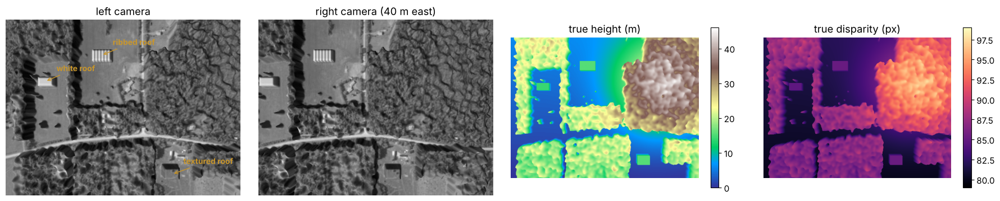

In [6]:
def roof_mask(name, P=PL):
    x, y, w, h, ht = BARNS[name]
    X0, Y0 = x * GSD, y * GSD
    return ((P[..., 0] > X0 + 1) & (P[..., 0] < X0 + w * GSD - 1) &
            (P[..., 1] > Y0 + 1) & (P[..., 1] < Y0 + h * GSD - 1) & (-P[..., 2] > ht - 1))
ROOFS = {n: roof_mask(n) for n in BARNS}
YY, XX = np.mgrid[0:H, 0:W]
CAN = cv2.remap(CANOPY, *to_ortho(PL[..., 0], PL[..., 1]), cv2.INTER_LINEAR)   # canopy height at each seen point
OPEN = (CAN < 0.5) & ~np.any([ROOFS[n] for n in BARNS], 0) & (np.abs(HGT - cv2.remap(GROUND, *to_ortho(PL[..., 0], PL[..., 1]), cv2.INTER_LINEAR)) < 0.3)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
axes[0].imshow(L, cmap="gray"); axes[0].set_title("left camera")
axes[1].imshow(R, cmap="gray"); axes[1].set_title(f"right camera ({B:.0f} m east)")
im = axes[2].imshow(HGT, cmap="terrain", vmin=0, vmax=46); axes[2].set_title("true height (m)")
fig.colorbar(im, ax=axes[2], shrink=0.8)
im = axes[3].imshow(D_TRUE, cmap="magma", vmin=79, vmax=99); axes[3].set_title("true disparity (px)")
fig.colorbar(im, ax=axes[3], shrink=0.8)
for n, m in ROOFS.items():
    yy, xx = np.argwhere(m).mean(0)
    axes[0].annotate(n, (xx, yy), (xx + 30, yy - 28), color=GOLD, fontsize=10, fontweight="bold",
                     arrowprops=dict(arrowstyle="->", color=GOLD))
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

The two images look almost the same — the whole scene has slid about 80 px to the left in the
right camera. But not *exactly* the same amount everywhere: things that are **higher** (closer
to the camera) slide **further**. That difference is the depth signal.

---
## 2 · Depth from disparity

A pinhole camera at the origin sends a point at $(X, Y, Z)$ to $x = f\,X/Z + c_x$ (L17 will
do cameras properly; this is all we need today). Put a second, identical camera $B$ metres
to the right. The same point lands at $x_R = f\,(X - B)/Z + c_x$, so the **disparity** is

$$d = x_L - x_R = \frac{f\,B}{Z} \qquad\Longleftrightarrow\qquad Z = \frac{f\,B}{d}.$$

Depth is inversely proportional to disparity. Near things move a lot between the views; the
horizon does not move at all.

In [7]:
def pixel_of(name):
    yy, xx = np.argwhere(ROOFS[name]).mean(0).round().astype(int); return yy, xx
yb, xb = pixel_of("textured roof")
tree = np.where(CAN > 5, HGT, -1)                                  # highest tree top in view
hill = np.where(OPEN & (XX >= 110), HGT, -1)                       # highest open ground
picks = {"field next to the textured barn": (yb, xb + 40),
         "textured barn roof": (yb, xb),
         "highest tree top": np.unravel_index(np.argmax(tree), HGT.shape),
         "hill top (open ground)": np.unravel_index(np.argmax(hill), HGT.shape)}
print(f"f = {F_PX:.0f} px, B = {B:.0f} m, flying height {HF:.0f} m\n")
print(f"{'pixel':34s}{'true d (px)':>12s}{'Z = fB/d (m)':>15s}{'height = 250 − Z':>19s}")
for name, (yy, xx) in picks.items():
    d = D_TRUE[yy, xx]; Z = F_PX * B / d
    print(f"{name:34s}{d:12.2f}{Z:15.1f}{HF - Z:17.1f} m")

f = 500 px, B = 40 m, flying height 250 m

pixel                              true d (px)   Z = fB/d (m)   height = 250 − Z
field next to the textured barn          80.72          247.8              2.2 m
textured barn roof                       85.25          234.6             15.4 m
highest tree top                         97.64          204.8             45.2 m
hill top (open ground)                   86.28          231.8             18.2 m


### 2.1 — How precise is stereo depth?

Differentiate $Z = fB/d$: an error of $\delta d$ pixels gives

$$\delta Z = \frac{Z^2}{f\,B}\,\delta d .$$

Depth error grows with the **square** of distance, and shrinks with a longer baseline or a
longer lens. For our drone, $Z^2/(fB) = 250^2/(500 \cdot 40) = 3.1$ m per pixel of disparity —
which is why sub-pixel disparity (section 9) matters.

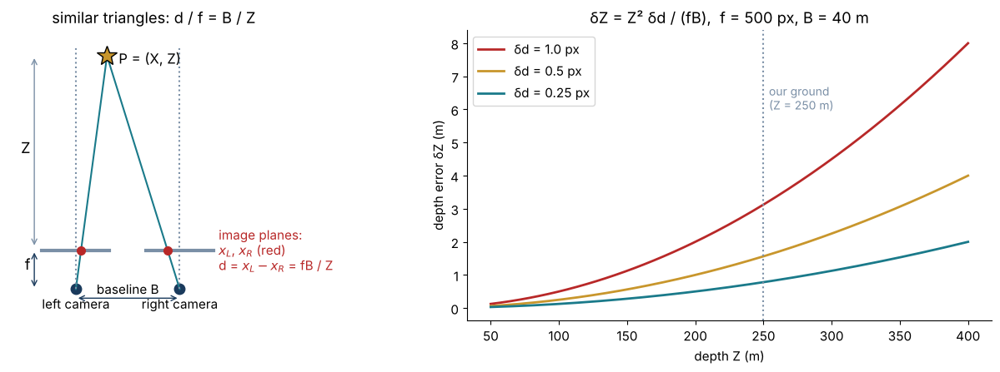

at Z = 250 m: one pixel of disparity = 3.12 m of depth


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]                                                   # the rectified stereo geometry
cL, cR, Zp, fz = np.array([0, 0]), np.array([4, 0]), 9.0, 1.5
P_ = np.array([1.2, Zp])
for c, lab in ((cL, "left camera"), (cR, "right camera")):
    ax.plot(*c, "o", ms=9, color=NAVY); ax.text(c[0], -0.75, lab, ha="center", fontsize=11)
    ax.plot([c[0] - 1.3, c[0] + 1.3], [fz, fz], color=GREY, lw=3)                  # image plane
    ax.plot([c[0], P_[0]], [c[1], P_[1]], color=TEAL, lw=1.5)                      # ray
    ax.plot([c[0], c[0]], [0, Zp + 0.3], ls=":", color=GREY)                        # optical axis
    xi = c[0] + (P_[0] - c[0]) * fz / Zp
    ax.plot(xi, fz, "o", color=RED, ms=7)
ax.plot(*P_, "*", ms=18, color=GOLD, mec="k"); ax.text(P_[0] + 0.45, P_[1] - 0.1, "P = (X, Z)", fontsize=12, va="center")
ax.annotate("", (cR[0], -0.35), (cL[0], -0.35), arrowprops=dict(arrowstyle="<->", color=NAVY))
ax.text(2, -0.3, "baseline B", ha="center", va="bottom", fontsize=11)
ax.annotate("", (-1.6, fz), (-1.6, 0), arrowprops=dict(arrowstyle="<->", color=NAVY))
ax.text(-1.75, fz / 2, "f", ha="right", fontsize=13)
ax.annotate("", (-1.6, Zp), (-1.6, fz + 0.1), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(-1.75, (Zp + fz) / 2, "Z", ha="right", fontsize=13)
ax.text(5.5, fz, "image planes:\n$x_L$, $x_R$ (red)\nd = $x_L - x_R$ = fB / Z", ha="left", va="center", fontsize=11, color=RED)
ax.set_xlim(-2.6, 8.6); ax.set_ylim(-1.2, 10); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("similar triangles: d / f = B / Z")

ax = axes[1]
Zs = np.linspace(50, 400, 200)
for dd, col in ((1.0, RED), (0.5, GOLD), (0.25, TEAL)):
    ax.plot(Zs, Zs**2 / (F_PX * B) * dd, color=col, lw=2, label=f"δd = {dd} px")
ax.axvline(HF, color=GREY, ls=":"); ax.text(HF + 4, 6.0, "our ground\n(Z = 250 m)", fontsize=10, color=GREY)
ax.set_xlabel("depth Z (m)"); ax.set_ylabel("depth error δZ (m)")
ax.set_title(f"δZ = Z² δd / (fB),  f = {F_PX:.0f} px, B = {B:.0f} m"); ax.legend()
plt.tight_layout(); plt.show()
print(f"at Z = 250 m: one pixel of disparity = {HF**2 / (F_PX * B):.2f} m of depth")

---
## 3 · Epipolar geometry

The neat sideways rig is a special case. In general the second camera is somewhere else and
pointed somewhere else. Make a third view, **C**: the drone has dropped 60 m, moved 18 m east
and 8 m south, and turned (8° yaw, 3° pitch, −3° roll).

Take a pixel $x$ in the left image. Its 3-D point lies somewhere on the ray through $x$. Seen
from camera C, that ray is a **line** — the **epipolar line** of $x$. The match of $x$ must
lie on it. All epipolar lines in one image pass through one point, the **epipole**: the image
of the other camera's centre.

In normalised camera coordinates $\hat x = K^{-1}x$, with $x_C = R(x_L) + t$ for the relative
pose, the three vectors $\hat x'$, $t$ and $R\hat x$ lie in one plane (the **epipolar plane**),
so

$$\hat x'^{\top}\,E\,\hat x = 0, \qquad E = [t]_\times R \quad\text{(essential matrix)}$$

$$x'^{\top}\,F\,x = 0, \qquad F = K'^{-\top} E\, K^{-1} \quad\text{(fundamental matrix, pixels)}$$

$[t]_\times$ is the cross-product matrix: $[t]_\times v = t \times v$.

In [9]:
def rot(yaw, pitch, roll):
    a, b, c = np.deg2rad([yaw, pitch, roll])
    Rz = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
    Ry = np.array([[np.cos(b), 0, np.sin(b)], [0, 1, 0], [-np.sin(b), 0, np.cos(b)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(c), -np.sin(c)], [0, np.sin(c), np.cos(c)]])
    return Rz @ Ry @ Rx

def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

R_C, C_C = rot(8, 3, -3), C_L + np.array([18.0, 8.0, 60.0])
Cim, ZC, PC = render(K, R_C, C_C, rng)

t_C = R_C @ (C_L - C_C)                            # pose of C relative to the left camera
E_TRUE = skew(t_C) @ R_C
Ki = np.linalg.inv(K)
F_TRUE = Ki.T @ E_TRUE @ Ki;  F_TRUE /= F_TRUE[2, 2]

def null_vec(M):
    v = np.linalg.svd(M)[2][-1]; return v / v[2]
e_L, e_C = null_vec(F_TRUE), null_vec(F_TRUE.T)    # F e_L = 0,  F^T e_C = 0
print(f"baseline |C_C − C_L| = {np.linalg.norm(C_C - C_L):.1f} m")
print(f"epipole in left image  ({e_L[0]:.1f}, {e_L[1]:.1f})")
print(f"epipole in image C     ({e_C[0]:.1f}, {e_C[1]:.1f})   — inside both images: C moved mostly forward (down)")
print("singular values of E:", np.linalg.svd(E_TRUE)[1].round(3), " (two equal, one zero)")
print("singular values of F:", np.linalg.svd(F_TRUE)[1].round(6), " (rank 2)")

baseline |C_C − C_L| = 63.2 m
epipole in left image  (470.0, 306.7)
epipole in image C     (485.3, 359.3)   — inside both images: C moved mostly forward (down)
singular values of E: [63.151 63.151  0.   ]  (two equal, one zero)
singular values of F: [1.000467e+00 4.660000e-04 0.000000e+00]  (rank 2)


Ground-truth correspondences come free from the renderer: take a grid of left pixels, look up
the 3-D point each one sees, project it into C, and keep it if C really sees that point (not
hidden behind a tree).

In [10]:
def project(P, R_, C_):
    x = (K @ (R_ @ (P.reshape(-1, 3) - C_).T)).T
    return x[:, :2] / x[:, 2:], x[:, 2]

def visible_in(P, R_, C_, Zimg):
    x, z = project(P, R_, C_)
    ok = (x[:, 0] >= 0) & (x[:, 0] < W - 1) & (x[:, 1] >= 0) & (x[:, 1] < H - 1)
    ok[ok] = np.abs(Zimg[x[ok, 1].round().astype(int), x[ok, 0].round().astype(int)] - z[ok]) < 1.0
    return x, ok

gv, gu = np.mgrid[8:H:16, 8:W:16]
xg, ok = visible_in(PL[gv, gu], R_C, C_C, ZC)
GT_L = np.stack([gu.ravel(), gv.ravel()], 1)[ok].astype(np.float64); GT_C = xg[ok]
GT_H = HGT[gv, gu].ravel()[ok]

def epi_dist(F, a, b):
    # symmetric distance (px) of b from the epipolar line F a, and of a from F^T b
    a3, b3 = np.c_[a, np.ones(len(a))], np.c_[b, np.ones(len(b))]
    l2, l1 = a3 @ F.T, b3 @ F
    r = np.abs(np.sum(l2 * b3, 1))
    return 0.5 * (r / np.hypot(l2[:, 0], l2[:, 1]) + r / np.hypot(l1[:, 0], l1[:, 1]))

print(f"{len(GT_L)} true correspondences;  median x'ᵀ F x = "
      f"{np.median(np.abs(np.sum(np.c_[GT_C, np.ones(len(GT_C))] * (np.c_[GT_L, np.ones(len(GT_L))] @ F_TRUE.T), 1))):.1e},"
      f"  median distance from the epipolar line {np.median(epi_dist(F_TRUE, GT_L, GT_C)):.1e} px")

651 true correspondences;  median x'ᵀ F x = 4.4e-16,  median distance from the epipolar line 6.5e-14 px


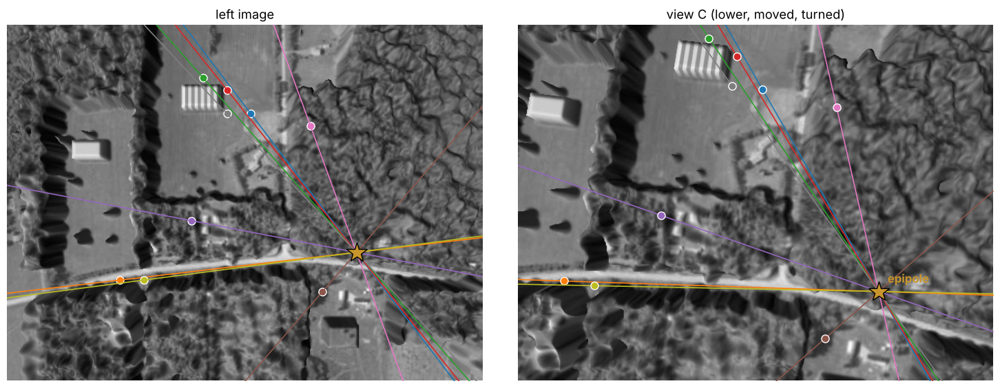

In [11]:
def draw_line(ax, l, color, lw=1.2):
    # l = (a, b, c): a x + b y + c = 0, clipped to the image
    a, b, c = l
    xs = np.array([0, W - 1.0])
    if abs(b) > 1e-9:
        ax.plot(xs, -(a * xs + c) / b, color=color, lw=lw)
    else:
        ax.plot([-c / a] * 2, [0, H - 1], color=color, lw=lw)

sel = np.random.default_rng(3).choice(len(GT_L), 9, replace=False)
cols = plt.cm.tab10(np.arange(9))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
axes[0].imshow(L, cmap="gray"); axes[1].imshow(Cim, cmap="gray")
for k, i in enumerate(sel):
    axes[0].plot(*GT_L[i], "o", color=cols[k], ms=8, mec="w")
    draw_line(axes[0], F_TRUE.T @ np.r_[GT_C[i], 1], cols[k])     # line in L of the point in C
    draw_line(axes[1], F_TRUE @ np.r_[GT_L[i], 1], cols[k])       # line in C of the point in L
    axes[1].plot(*GT_C[i], "o", color=cols[k], ms=8, mec="w")
for ax, e, t in ((axes[0], e_L, "left image"), (axes[1], e_C, "view C (lower, moved, turned)")):
    ax.plot(e[0], e[1], "*", ms=22, color=GOLD, mec="k"); ax.set_title(t)
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis("off")
axes[1].text(e_C[0] + 12, e_C[1] - 12, "epipole", color=GOLD, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

Each coloured point in the left image has a coloured **line** in C, and its true match sits
exactly on it. All the lines in C meet at the epipole (gold star) — where the left camera's
centre would appear in C. Because C moved mostly **towards** the ground, the epipole is
inside the image: it is L10's **focus of expansion**.

### 3.1 — The special case: a sideways rig

For our left–right pair, $R = I$ and $t = (-B, 0, 0)$. Then

$$E = [t]_\times = \begin{pmatrix}0&0&0\\0&0&B\\0&-B&0\end{pmatrix},\qquad
E\,\hat x = (0,\; B,\; -B\hat y),\qquad \hat x'^{\top}E\,\hat x = B\,(\hat y' - \hat y) = 0 \;\Rightarrow\; y' = y.$$

**The epipolar lines are the image rows.** The epipole is at infinity along $x$. That is why
a stereo rig only searches along rows — and why L10's leftover 1958 motion was (almost) all
along $x$.

In [12]:
E_LR = skew(np.array([-B, 0, 0]))                 # R = I,  t = R (C_L − C_R) = (−B, 0, 0)
F_LR = Ki.T @ E_LR @ Ki
print("F for the left–right pair (scaled so the largest entry is 1):")
print((F_LR / np.abs(F_LR).max()).round(4))
l = F_LR @ np.array([100.0, 250.0, 1.0])
print(f"epipolar line of left pixel (100, 250) in the right image: {l[0]:.3g}·x + {l[1]:.3g}·y + {l[2]:.3g} = 0"
      f"  →  y = {-l[2] / l[1]:.1f}")

F for the left–right pair (scaled so the largest entry is 1):
[[ 0.  0.  0.]
 [ 0.  0.  1.]
 [ 0. -1.  0.]]
epipolar line of left pixel (100, 250) in the right image: 0·x + 0.08·y + -20 = 0  →  y = 250.0


---
## 4 · Estimating $F$ from matches

In practice we don't know the pose; we estimate $F$ from point matches — L7's SIFT, L8's
RANSAC. Each match gives **one linear equation** in the nine entries of $F$:

$$x'x\,f_{11} + x'y\,f_{12} + x'\,f_{13} + y'x\,f_{21} + y'y\,f_{22} + y'\,f_{23} + x\,f_{31} + y\,f_{32} + f_{33} = 0.$$

$F$ has scale ambiguity (8 unknowns), so **eight matches** determine it — the **eight-point
algorithm** (Longuet-Higgins 1981; Hartley 1997). Stack the rows into $A f = 0$ and take the
last right singular vector of $A$ — exactly the homography DLT of L8. Two extra steps:

1. **Normalise** the points first (centre them, scale to mean distance √2), as in L8.
2. **Enforce rank 2**: a true $F$ is singular (all epipolar lines must meet at one epipole).
   Take the SVD $F = U\,\mathrm{diag}(\sigma_1,\sigma_2,\sigma_3)V^\top$, set $\sigma_3 = 0$
   — L9's best low-rank approximation.

In [13]:
sift = cv2.SIFT_create()
kl, dl = sift.detectAndCompute(L, None); kc, dc = sift.detectAndCompute(Cim, None)
knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(dl, dc, k=2)
good = [m for m, n in knn if m.distance < 0.75 * n.distance]
pl = np.float64([kl[m.queryIdx].pt for m in good]); pc = np.float64([kc[m.trainIdx].pt for m in good])
true_pc, _ = project(PL[pl[:, 1].round().astype(int), pl[:, 0].round().astype(int)], R_C, C_C)
CORRECT = np.linalg.norm(true_pc - pc, axis=1) < 2                 # within 2 px of the truth
print(f"SIFT: {len(kl)} and {len(kc)} keypoints, {len(good)} matches after the ratio test, "
      f"{CORRECT.mean():.1%} correct")

SIFT: 2748 and 1585 keypoints, 1012 matches after the ratio test, 96.3% correct


In [14]:
def normaliser(p):
    c = p.mean(0); s = np.sqrt(2) / np.mean(np.linalg.norm(p - c, axis=1))
    return np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1]])

def eight_point(a, b, normalise=True, rank2=True):
    Ta, Tb = (normaliser(a), normaliser(b)) if normalise else (np.eye(3), np.eye(3))
    x = (Ta @ np.c_[a, np.ones(len(a))].T).T; y = (Tb @ np.c_[b, np.ones(len(b))].T).T
    A = np.stack([y[:, 0]*x[:, 0], y[:, 0]*x[:, 1], y[:, 0], y[:, 1]*x[:, 0], y[:, 1]*x[:, 1], y[:, 1],
                  x[:, 0], x[:, 1], np.ones(len(x))], 1)
    Fn = np.linalg.svd(A)[2][-1].reshape(3, 3)                       # A f = 0, least squares
    if rank2:
        U, S, Vt = np.linalg.svd(Fn); S[2] = 0; Fn = U @ np.diag(S) @ Vt   # nearest rank-2 matrix
    F = Tb.T @ Fn @ Ta                                                # undo the normalisation
    return F / F[2, 2]

ia, ic = pl[CORRECT], pc[CORRECT]
F_raw, F_r2 = eight_point(ia, ic, rank2=False), eight_point(ia, ic)
sv = np.linalg.svd(F_raw)[1]
print(f"all {len(ia)} correct matches, before rank-2 enforcement: σ₃/σ₂ = {sv[2] / sv[1]:.1e} (not zero);"
      f"  error {np.median(epi_dist(F_raw, GT_L, GT_C)):.3f} px → {np.median(epi_dist(F_r2, GT_L, GT_C)):.3f} px after")

rs = np.random.default_rng(0)
EIGHT = {}
for nrm in (False, True):
    errs = [np.median(epi_dist(eight_point(ia[i], ic[i], nrm), GT_L, GT_C))
            for i in (rs.choice(len(ia), 8, replace=False) for _ in range(300))]
    EIGHT[nrm] = (np.median(errs), np.median(epi_dist(eight_point(ia, ic, nrm), GT_L, GT_C)))
    print(f"normalise={nrm!s:5s}: 8 random correct matches → median error {EIGHT[nrm][0]:.2f} px (300 trials);"
          f"  all {len(ia)} correct → {EIGHT[nrm][1]:.3f} px")
A_raw = np.c_[ia, np.ones(len(ia))]
print(f"(raw pixel coordinates mix entries of size ~1 and ~{np.abs(ia).max()**2:.0e} in A)")

all 975 correct matches, before rank-2 enforcement: σ₃/σ₂ = 5.2e-07 (not zero);  error 0.100 px → 0.102 px after
normalise=False: 8 random correct matches → median error 0.81 px (300 trials);  all 975 correct → 0.105 px


normalise=True : 8 random correct matches → median error 0.74 px (300 trials);  all 975 correct → 0.102 px
(raw pixel coordinates mix entries of size ~1 and ~3e+05 in A)


Score each $F$ by how far the **true** correspondences of section 3 sit from its epipolar
lines. Eight matches give an $F$ good to about a pixel; all the correct ones, to a tenth of a
pixel. Normalisation helps only a little on this pair (as with the homography in L8). But our matches contain wrong ones too, and least squares is wrecked by a single
outlier (L8). So: **RANSAC**, with 8-point (or 7-point) samples and the point-to-line distance
as the residual.

In [15]:
FITS = {}
cv2.setRNGSeed(0)
F_ls = eight_point(pl, pc)                                              # every match, wrong ones too
FITS["8-point on all matches (no RANSAC)"] = (F_ls, np.ones(len(pl), bool))
for name, method in (("RANSAC (1 px)", cv2.FM_RANSAC), ("MAGSAC (1 px)", cv2.USAC_MAGSAC)):
    F_, m_ = cv2.findFundamentalMat(pl, pc, method, 1.0, 0.999)
    FITS[name] = (F_ / F_[2, 2], m_.ravel() > 0)
print(f"{'':36s}{'inliers':>9s}{'precision':>11s}{'median err':>12s}{'95th pct':>10s}   (error vs true correspondences, px)")
for name, (F_, m_) in FITS.items():
    e = epi_dist(F_, GT_L, GT_C)
    print(f"{name:36s}{m_.sum():9d}{CORRECT[m_].mean():11.1%}{np.median(e):12.3f}{np.percentile(e, 95):10.3f}")
F_EST, IN_F = FITS["MAGSAC (1 px)"]

                                      inliers  precision  median err  95th pct   (error vs true correspondences, px)
8-point on all matches (no RANSAC)       1012      96.3%       1.253     5.206
RANSAC (1 px)                             929      98.5%       0.222     0.823
MAGSAC (1 px)                             993      97.8%       0.099     0.153


### 4.1 — Why not a homography?

L8 fitted a **homography** to the 1958 pair. A homography maps a point to a **point**; it is
exact only when every point is on one plane (or the camera only rotates). $F$ maps a point to
a **line** and holds for any 3-D scene. Fit both to the correct matches and see how the
residual depends on the height of the point:

homography (MAGSAC 3 px): 772 of 975 correct matches are inliers; median transfer error 1.48 px, 95th pct 5.6 px
fundamental matrix:       median point-to-line error 0.10 px, 95th pct 0.54 px


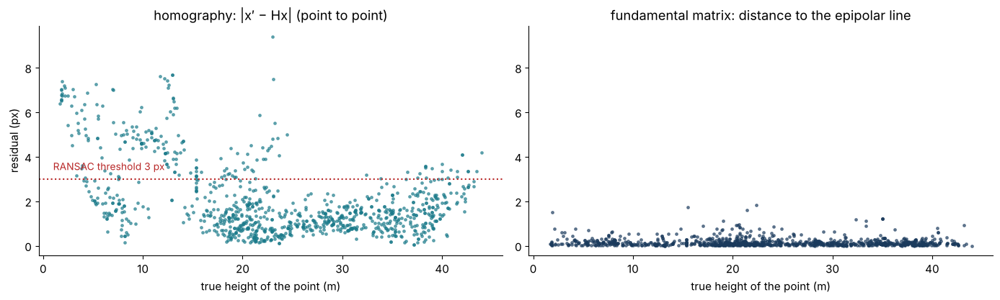

In [16]:
cv2.setRNGSeed(0)
H_C, inH = cv2.findHomography(ia, ic, cv2.USAC_MAGSAC, 3.0)
res_H = np.linalg.norm(cv2.perspectiveTransform(ia[None], H_C)[0] - ic, axis=1)
res_F = epi_dist(F_EST, ia, ic)
h_pts = HGT[ia[:, 1].round().astype(int), ia[:, 0].round().astype(int)]
print(f"homography (MAGSAC 3 px): {inH.sum()} of {len(ia)} correct matches are inliers; "
      f"median transfer error {np.median(res_H):.2f} px, 95th pct {np.percentile(res_H, 95):.1f} px")
print(f"fundamental matrix:       median point-to-line error {np.median(res_F):.2f} px, "
      f"95th pct {np.percentile(res_F, 95):.2f} px")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharex=True)
axes[0].scatter(h_pts, res_H, s=6, c=TEAL, alpha=0.6)
axes[0].axhline(3, color=RED, ls=":"); axes[0].text(1, 3.4, "RANSAC threshold 3 px", color=RED, fontsize=10)
axes[0].set_title("homography: |x′ − Hx| (point to point)"); axes[0].set_ylabel("residual (px)")
axes[1].scatter(h_pts, res_F, s=6, c=NAVY, alpha=0.6); axes[1].set_ylim(axes[0].get_ylim())
axes[1].set_title("fundamental matrix: distance to the epipolar line")
for a in axes: a.set_xlabel("true height of the point (m)")
plt.tight_layout(); plt.show()

The homography locks onto the most common height — the woodland canopy around 20 m, where
most SIFT points are — and its error grows for points above or below it: one plane cannot
explain points at different heights, so its residual **is** the height signal (L8's "RANSAC
residuals", L10's leftover flow). $F$ has no idea about heights — every true match lies on its line —
which is exactly why we need one more step to get depth: *where* along the line.

---
## 5 · From $E$ to camera pose to 3-D points

If we know $K$ (calibration, L17), we can work with $E$ directly: 5 degrees of freedom
(3 rotation + 2 for the direction of $t$), solvable from **five** matches (Nistér 2004),
inside RANSAC. $E$ factors into the rotation and translation between the cameras;
`cv2.recoverPose` tries the four possible factorisations and keeps the one that puts the
points **in front of** both cameras.

In [17]:
cv2.setRNGSeed(0)
E_est, mE = cv2.findEssentialMat(pl, pc, K, cv2.USAC_MAGSAC, 0.999, 1.0)
_, R_est, t_est, _ = cv2.recoverPose(E_est, pl, pc, K, mask=mE.copy())
rot_err = np.degrees(np.arccos(np.clip((np.trace(R_est.T @ R_C) - 1) / 2, -1, 1)))
t_dir = t_C / np.linalg.norm(t_C)
t_err = np.degrees(np.arccos(np.clip(t_est.ravel() @ t_dir, -1, 1)))
print(f"essential matrix: {mE.sum()} inliers")
print(f"rotation error {rot_err:.3f}°;  translation direction error {t_err:.3f}°")
print(f"estimated t direction {t_est.ravel().round(3)},  true {t_dir.round(3)},  |t| = 1 always")

essential matrix: 993 inliers
rotation error 0.022°;  translation direction error 0.112°
estimated t direction [-0.308 -0.222 -0.925],  true [-0.306 -0.221 -0.926],  |t| = 1 always


The translation comes out as a **unit vector**: from images alone, a scene twice as big
photographed from twice as far apart looks identical. This is the **scale ambiguity** of
two-view geometry. Fix it with one known length — here the true distance between the cameras
(a drone's GPS would give it) — and **triangulate**: intersect the two rays of each match.

triangulated 993 points; on the correct ones, height error median 0.40 m, 95th pct 3.16 m


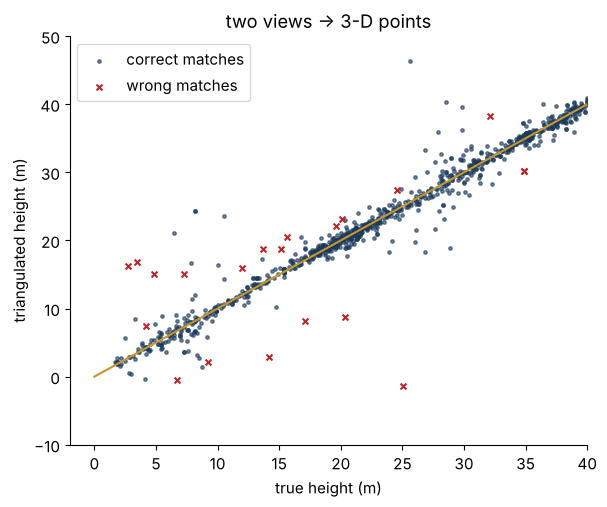

In [18]:
baseline = np.linalg.norm(C_C - C_L)
P1 = K @ np.hstack([np.eye(3), np.zeros((3, 1))])
P2 = K @ np.hstack([R_est, t_est * baseline])
inl = mE.ravel() > 0
X = cv2.triangulatePoints(P1, P2, pl[inl].T, pc[inl].T)
X = (X[:3] / X[3]).T                                         # in the left camera's frame
h_est = HF - X[:, 2]                                         # left camera looks straight down from 250 m
h_true = HGT[pl[inl, 1].round().astype(int), pl[inl, 0].round().astype(int)]
ok = CORRECT[inl]
err = np.abs(h_est - h_true)[ok]
print(f"triangulated {inl.sum()} points; on the correct ones, height error median {np.median(err):.2f} m, "
      f"95th pct {np.percentile(err, 95):.2f} m")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.scatter(h_true[ok], h_est[ok], s=6, color=NAVY, alpha=0.6, label="correct matches")
ax.scatter(h_true[~ok], h_est[~ok], s=18, color=RED, marker="x", label="wrong matches")
ax.plot([0, 40], [0, 40], color=GOLD, lw=1.5); ax.set_xlim(-2, 40); ax.set_ylim(-10, 50)
ax.set_xlabel("true height (m)"); ax.set_ylabel("triangulated height (m)")
ax.set_title("two views → 3-D points"); ax.legend()
plt.tight_layout(); plt.show()

---
## 6 · Rectification

Sparse matches give a few hundred 3-D points. For a depth value at **every** pixel we search
along the epipolar line of every pixel — easiest when the lines are the image **rows**, as in
the sideways rig of section 3.1. **Rectification** warps both images (one homography each,
a rotation about each camera centre) so that they are.

Real rigs are never perfectly aligned. Make one: the right camera is "bumped" by
0.6° yaw, −0.4° pitch and 0.8° roll — less than one degree each.

In [19]:
R_bump = rot(0.6, -0.4, 0.8)
Rb, ZRb, _ = render(K, R_bump, C_R, rng)

def true_offsets(Rcam, Ccam, Zcam):
    x, ok = visible_in(PL, Rcam, Ccam, Zcam)
    x = x.reshape(H, W, 2); ok = ok.reshape(H, W)
    XX_, YY_ = np.meshgrid(np.arange(W), np.arange(H))
    return XX_ - x[..., 0], x[..., 1] - YY_, ok             # horizontal disparity, vertical offset, visible

dx_b, dy_b, vis_b = true_offsets(R_bump, C_R, ZRb)
print(f"bumped rig: true vertical offset between matching pixels {np.percentile(dy_b[vis_b], 1):+.1f} .. "
      f"{np.percentile(dy_b[vis_b], 99):+.1f} px (1st..99th pct)")

T_b = R_bump @ (C_L - C_R)                                    # relative pose, left → bumped right
R1, R2, P1r, P2r, Qm, _, _ = cv2.stereoRectify(K, np.zeros(5), K, np.zeros(5), (W, H), R_bump, T_b.reshape(3, 1), alpha=0)
m1 = cv2.initUndistortRectifyMap(K, np.zeros(5), R1, P1r, (W, H), cv2.CV_32FC1)
m2 = cv2.initUndistortRectifyMap(K, np.zeros(5), R2, P2r, (W, H), cv2.CV_32FC1)
L_rect = cv2.remap(L, *m1, cv2.INTER_LINEAR); R_rect = cv2.remap(Rb, *m2, cv2.INTER_LINEAR)

def match_dy(A, Bimg):
    ka_, da_ = sift.detectAndCompute(A, None); kb_, db_ = sift.detectAndCompute(Bimg, None)
    g_ = [m for m, n in cv2.BFMatcher().knnMatch(da_, db_, k=2) if m.distance < 0.7 * n.distance]
    a_ = np.float32([ka_[m.queryIdx].pt for m in g_]); b_ = np.float32([kb_[m.trainIdx].pt for m in g_])
    return a_, b_
a0, b0 = match_dy(L, Rb); a1, b1 = match_dy(L_rect, R_rect)
d0, d1 = b0[:, 1] - a0[:, 1], b1[:, 1] - a1[:, 1]
good0 = np.abs(a0[:, 0] - b0[:, 0] - np.median(a0[:, 0] - b0[:, 0])) < 20         # drop the few wrong matches
good1 = np.abs(a1[:, 0] - b1[:, 0] - np.median(a1[:, 0] - b1[:, 0])) < 20
print(f"SIFT matches, |y′ − y|:  before {np.median(np.abs(d0[good0])):.2f} px median, "
      f"{np.percentile(np.abs(d0[good0]), 95):.2f} px 95th pct;   after rectification "
      f"{np.median(np.abs(d1[good1])):.2f} / {np.percentile(np.abs(d1[good1]), 95):.2f} px")

bumped rig: true vertical offset between matching pixels -11.8 .. -4.8 px (1st..99th pct)


SIFT matches, |y′ − y|:  before 7.36 px median, 10.33 px 95th pct;   after rectification 0.10 / 0.72 px


In [20]:
def sgbm(minD=64, numD=48, bs=5, mode=cv2.STEREO_SGBM_MODE_SGBM, **kw):
    return cv2.StereoSGBM_create(minDisparity=minD, numDisparities=numD, blockSize=bs,
                                 P1=8 * bs * bs, P2=32 * bs * bs, uniquenessRatio=10, mode=mode, **kw)

def bad1(D, Dt, valid):
    e = np.abs(D - Dt)[valid]
    return np.mean(~(e <= 1)), np.nanmedian(e)               # missing values count as bad

EV_B = vis_b.copy(); EV_B[:, :110] = False; EV_B[:12] = EV_B[-12:] = False
D_un = sgbm().compute(L, Rb).astype(np.float32) / 16; D_un[D_un < 64] = np.nan
b_un, m_un = bad1(D_un, dx_b, EV_B)

# ground truth in the rectified left image: the 3-D point behind each rectified pixel
XX_, YY_ = np.meshgrid(np.arange(W), np.arange(H))
P_r = np.dstack([cv2.remap(PL[..., k].astype(np.float32), *m1, cv2.INTER_NEAREST) for k in range(3)])
Zr = (R1 @ (P_r.reshape(-1, 3) - C_L).T)[2].reshape(H, W)
fr, Br = P1r[0, 0], np.linalg.norm(T_b)
D_true_r = fr * Br / Zr + (P1r[0, 2] - P2r[0, 2])
D_re = sgbm().compute(L_rect, R_rect).astype(np.float32) / 16; D_re[D_re < 64] = np.nan
EV_R = (cv2.remap(np.ones((H, W), np.float32), *m1, cv2.INTER_NEAREST) > 0) & (XX_ > 110)
EV_R[:12] = EV_R[-12:] = False
b_re, m_re = bad1(D_re, D_true_r, EV_R)
print(f"SGBM on the bumped pair:     {b_un:.1%} of pixels wrong by > 1 px (median error {m_un:.2f} px)")
print(f"SGBM after rectification:    {b_re:.1%}  (median {m_re:.2f} px)")
print(f"rectified focal length {fr:.1f} px, baseline {Br:.2f} m")

SGBM on the bumped pair:     87.5% of pixels wrong by > 1 px (median error 5.11 px)
SGBM after rectification:    6.8%  (median 0.22 px)
rectified focal length 518.7 px, baseline 40.00 m


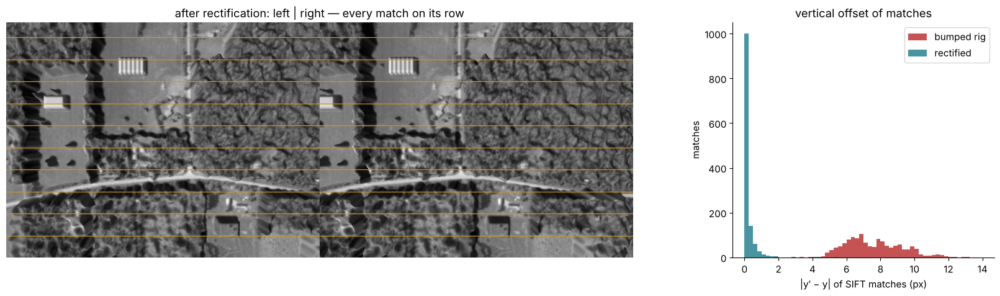

In [21]:
fig = plt.figure(figsize=(17, 4.9))
gs = fig.add_gridspec(1, 2, width_ratios=[2.75, 1])
ax = fig.add_subplot(gs[0]); ax.imshow(np.hstack([L_rect, R_rect]), cmap="gray")
for y in range(30, H, 45):
    ax.axhline(y, color=GOLD, lw=0.9)
ax.set_title("after rectification: left | right — every match on its row"); ax.axis("off")
ax = fig.add_subplot(gs[1]); bins = np.linspace(0, 14, 57)
ax.hist(np.abs(d0[good0]), bins, color=RED, alpha=0.8, label="bumped rig")
ax.hist(np.abs(d1[good1]), bins, color=TEAL, alpha=0.8, label="rectified")
ax.set_xlabel("|y′ − y| of SIFT matches (px)"); ax.set_ylabel("matches"); ax.legend()
ax.set_title("vertical offset of matches")
plt.tight_layout(); plt.show()

Before: matches are 5–12 px off their row — less than a degree of pitch and roll does that,
and SGBM gets almost nothing right. After rectification every match is on its row, and a
row-by-row search works again. Without calibration you can rectify from $F$ alone
(`cv2.stereoRectifyUncalibrated`, section 11). **View C cannot be rectified this way**: its
epipole is *inside* the image, and no homography can send it to infinity without tearing
the image apart (self-check).

---
## 7 · Dense matching by hand: the cost volume

On a rectified pair, the match of left pixel $(x, y)$ is right pixel $(x - d, y)$ for some
disparity $d$. For every candidate $d$, compare a small window around $(x, y)$ in the left
image with the window around $(x - d, y)$ in the right. Stack the costs into a **cost volume**
$C(d, y, x)$ and take, at each pixel, the $d$ with the lowest cost (**winner takes all**).

Costs: **SAD** (sum of absolute differences), **SSD**, or **ZNCC** (zero-mean normalised
cross-correlation — L3's template matching), which ignores brightness offset and gain.

In [22]:
DMIN, DMAX = 72, 104                                        # search range (px)
xr = np.round(XX - D_TRUE).astype(int)
OCC = (xr < 0) | (ZR[YY, np.clip(xr, 0, W - 1)] < ZL - 0.5)      # not visible in the right image
EVAL = ~OCC; EVAL[:, :DMAX] = False; EVAL[:12] = EVAL[-12:] = False; EVAL[:, -12:] = False
print(f"{(OCC & (XX >= DMAX)).mean():.1%} of the left image is occluded in the right; "
      f"we score on {EVAL.mean():.0%} of pixels (left {DMAX} columns have no partner)")

def cost_volume(Lf, Rf, w, kind="SAD"):
    Lf, Rf = Lf.astype(np.float32), Rf.astype(np.float32)
    ds = np.arange(DMIN, DMAX + 1)
    Cv = np.full((len(ds), H, W), np.inf, np.float32)
    box = lambda z: cv2.boxFilter(z, -1, (w, w), borderType=cv2.BORDER_REFLECT)   # window mean
    if kind == "ZNCC":
        mL = box(Lf); sL = np.sqrt(np.maximum(box(Lf * Lf) - mL**2, 1e-3))
    for i, d in enumerate(ds):
        Rs = np.zeros_like(Rf); Rs[:, d:] = Rf[:, :W - d]                   # Rs(x, y) = R(x − d, y)
        if kind == "SAD":
            c = box(np.abs(Lf - Rs))
        elif kind == "SSD":
            c = box((Lf - Rs) ** 2)
        else:
            mR = box(Rs); sR = np.sqrt(np.maximum(box(Rs * Rs) - mR**2, 1e-3))
            c = 1 - (box(Lf * Rs) - mL * mR) / (sL * sR)                      # 1 − correlation
        c[:, :d] = np.inf
        Cv[i] = c
    return ds, Cv

def wta(ds, Cv, subpix=True):
    i = np.argmin(Cv, 0)
    d = ds[i].astype(np.float32)
    if subpix:                                              # fit a parabola through 3 costs (section 9)
        ii = np.clip(i, 1, len(ds) - 2)
        c0, c1, c2 = (np.take_along_axis(Cv, (ii + k)[None], 0)[0] for k in (-1, 0, 1))
        with np.errstate(invalid="ignore", divide="ignore"):
            den = c0 - 2 * c1 + c2
            off = np.where((den > 0) & np.isfinite(den) & (i == ii), 0.5 * (c0 - c2) / den, 0)
        d = d + np.clip(np.nan_to_num(off), -0.5, 0.5)
    return d

def score(D, mask=None):
    e = np.abs(D - D_TRUE)[EVAL if mask is None else mask]
    return np.nanmedian(e), np.mean(~(e <= 1)), np.mean(~(e <= 2))

t0 = time.perf_counter()
ds, CV7 = cost_volume(L, R, 7, "SAD")
print(f"cost volume: {CV7.shape[0]} disparities × {H} × {W}, {1000 * (time.perf_counter() - t0):.0f} ms")

1.8% of the left image is occluded in the right; we score on 76% of pixels (left 104 columns have no partner)
cost volume: 33 disparities × 480 × 640, 68 ms


### 7.1 — What one pixel's cost curve looks like

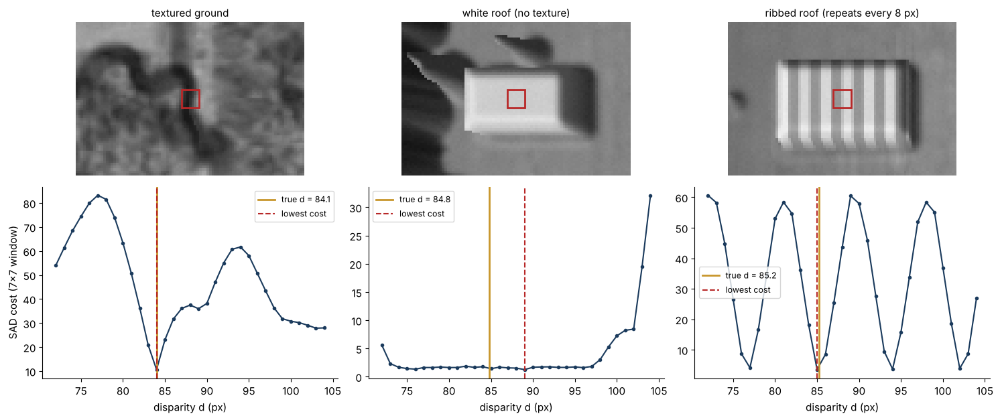

In [23]:
gm = cv2.boxFilter(np.abs(cv2.Sobel(L, cv2.CV_32F, 1, 0)), -1, (7, 7))
gm[~EVAL | (np.abs(XX - 380) > 40) | (np.abs(YY - 240) > 40)] = 0
spots = {"textured ground": np.unravel_index(np.argmax(gm), gm.shape),
         "white roof (no texture)": pixel_of("white roof"),
         "ribbed roof (repeats every 8 px)": pixel_of("ribbed roof")}
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), gridspec_kw={"height_ratios": [1, 1.25]})
for k, (name, (yy, xx)) in enumerate(spots.items()):
    axes[0, k].imshow(L[yy - 30:yy + 31, xx - 45:xx + 46], cmap="gray", vmin=0, vmax=255)
    axes[0, k].add_patch(plt.Rectangle((45 - 3.5, 30 - 3.5), 7, 7, fill=False, color=RED, lw=2))
    axes[0, k].set_title(name, fontsize=11); axes[0, k].axis("off")
    axes[1, k].plot(ds, CV7[:, yy, xx], "-o", ms=3, color=NAVY)
    axes[1, k].axvline(D_TRUE[yy, xx], color=GOLD, lw=2, label=f"true d = {D_TRUE[yy, xx]:.1f}")
    axes[1, k].axvline(ds[np.argmin(CV7[:, yy, xx])], color=RED, ls="--", label="lowest cost")
    axes[1, k].set_xlabel("disparity d (px)"); axes[1, k].legend(fontsize=9)
axes[1, 0].set_ylabel("SAD cost (7×7 window)")
plt.tight_layout(); plt.show()

Textured: one sharp minimum at the right place. White roof: a flat valley — every disparity
across the roof looks equally good, and noise picks the winner. Ribbed roof: a minimum every
8 px — the stripes repeat along the epipolar line, so several disparities fit perfectly.

### 7.2 — Window size

In [24]:
WIN = {}
for kind in ("SAD", "ZNCC"):
    for w in ((3, 7, 11, 21) if kind == "SAD" else (7, 11)):
        t0 = time.perf_counter()
        D = wta(*cost_volume(L, R, w, kind)) if (kind, w) != ("SAD", 7) else wta(ds, CV7)
        WIN[(kind, w)] = (D, 1000 * (time.perf_counter() - t0))
print(f"{'cost, window':16s}{'median err':>11s}{'> 1 px':>9s}{'> 2 px':>9s}{'white roof >1':>15s}{'ribbed >1':>11s}")
for (kind, w), (D, ms) in WIN.items():
    m, b1_, b2_ = score(D)
    print(f"{kind + f', {w}×{w}':16s}{m:11.2f}{b1_:9.1%}{b2_:9.1%}"
          f"{score(D, ROOFS['white roof'])[1]:15.1%}{score(D, ROOFS['ribbed roof'])[1]:11.1%}")

cost, window     median err   > 1 px   > 2 px  white roof >1  ribbed >1
SAD, 3×3               0.18    13.7%    10.1%          63.6%      43.9%
SAD, 7×7               0.12     4.3%     2.5%          54.7%      34.3%
SAD, 11×11             0.14     4.9%     2.6%          49.0%      25.4%
SAD, 21×21             0.24    10.7%     4.9%          34.6%      10.3%
ZNCC, 7×7              0.16     8.5%     5.4%          56.2%      38.8%
ZNCC, 11×11            0.17     7.8%     4.0%          47.0%      25.7%


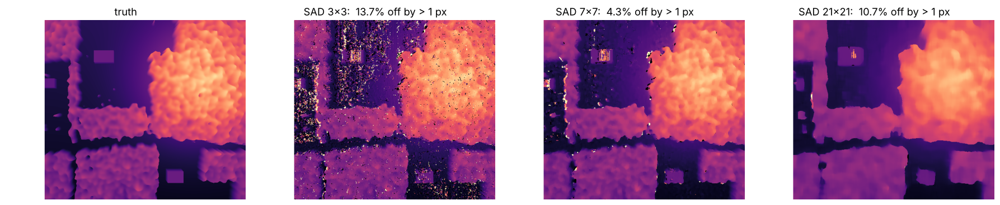

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
show = [("truth", D_TRUE)] + [(f"SAD {w}×{w}", WIN[("SAD", w)][0]) for w in (3, 7, 21)]
for ax, (ttl, D) in zip(axes, show):
    ax.imshow(np.where(XX >= DMAX, D, np.nan), cmap="magma", vmin=79, vmax=99)
    if ttl != "truth":
        m, b1_, _ = score(D); ttl += f":  {b1_:.1%} off by > 1 px"
    ax.set_title(ttl); ax.axis("off")
plt.tight_layout(); plt.show()

Same trade-off as L10's flow windows: **small windows** are noisy (not enough texture to be
sure); **large windows** blur depth edges — a 21×21 window straddling a woodlot edge
mixes canopy and field. 7–11 px is the sweet spot here. ZNCC is slightly worse than SAD on
this pair (it throws away the brightness information, which here is reliable); section 12
shows when it wins.

---
## 8 · OpenCV: StereoBM and semi-global matching

`cv2.StereoBM` is block matching (SAD after a prefilter) with validity checks. **Semi-global
matching** (SGM, Hirschmüller 2008; `cv2.StereoSGBM`) adds **smoothness**: along 5 or 8
directions through the image it penalises a disparity change of 1 px by `P1` and a larger jump
by `P2`, then sums. Like Horn–Schunck in L10: the data term plus "neighbours usually agree",
but with a cheap penalty for genuine depth edges.

Both return disparity × 16 as integers (4 fractional bits).

In [26]:
bm = cv2.StereoBM_create(numDisparities=48, blockSize=15); bm.setMinDisparity(64)
t0 = time.perf_counter(); D_bm = bm.compute(L, R).astype(np.float32) / 16; t_bm = time.perf_counter() - t0
D_bm[D_bm < 64] = np.nan                                     # −1 → 'no answer'
DENSE = {"SAD 7×7 (ours)": (WIN[("SAD", 7)][0], WIN[("SAD", 7)][1]), "StereoBM 15×15": (D_bm, 1000 * t_bm)}
for bs in (3, 5, 7):
    t0 = time.perf_counter(); D = sgbm(bs=bs).compute(L, R).astype(np.float32) / 16
    D[D < 64] = np.nan; DENSE[f"SGBM, block {bs}"] = (D, 1000 * (time.perf_counter() - t0))
D_SG = DENSE["SGBM, block 5"][0]

print(f"{'':18s}{'median':>8s}{'> 1 px':>9s}{'> 2 px':>9s}{'answered':>10s}{'white':>8s}{'ribbed':>8s}{'textured':>10s}{'ms':>6s}")
for name, (D, ms) in DENSE.items():
    m, b1_, b2_ = score(D)
    roofs = [score(D, ROOFS[n])[1] for n in BARNS]
    print(f"{name:18s}{m:8.2f}{b1_:9.1%}{b2_:9.1%}{np.isfinite(D)[EVAL].mean():10.0%}"
          + "".join(f"{r:8.0%}" for r in roofs[:2]) + f"{roofs[2]:10.0%}{ms:6.0f}")
print("(roof columns: share of roof pixels off by > 1 px, or with no answer)")

                    median   > 1 px   > 2 px  answered   white  ribbed  textured    ms
SAD 7×7 (ours)        0.12     4.3%     2.5%      100%     55%     34%        4%    46
StereoBM 15×15        0.17    11.1%     8.6%       93%     78%     66%        2%    13
SGBM, block 3         0.20     5.5%     3.4%       98%     68%      0%        0%    41
SGBM, block 5         0.20     6.0%     3.6%       98%     68%      0%        0%    39
SGBM, block 7         0.22     6.8%     3.8%       98%     69%      0%        0%    38
(roof columns: share of roof pixels off by > 1 px, or with no answer)


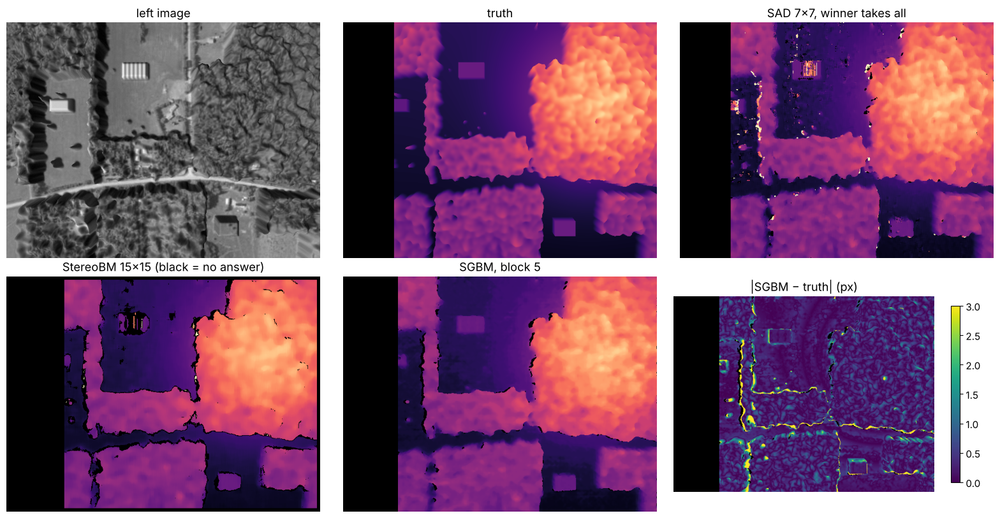

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.2))
panels = [("left image", L, "gray", None), ("truth", D_TRUE, "magma", (79, 99)),
          ("SAD 7×7, winner takes all", WIN[("SAD", 7)][0], "magma", (79, 99)),
          ("StereoBM 15×15 (black = no answer)", D_bm, "magma", (79, 99)),
          ("SGBM, block 5", D_SG, "magma", (79, 99)),
          ("|SGBM − truth| (px)", np.abs(D_SG - D_TRUE), "viridis", (0, 3))]
for ax, (ttl, im_, cmap, rng_) in zip(axes.ravel(), panels):
    show_ = im_ if cmap == "gray" else np.where((XX >= DMAX) & np.isfinite(im_), im_, np.nan)
    kw = dict(vmin=rng_[0], vmax=rng_[1]) if rng_ else {}
    cm = plt.get_cmap(cmap).copy(); cm.set_bad("black")
    h_ = ax.imshow(show_, cmap=cm, **kw); ax.set_title(ttl); ax.axis("off")
fig.colorbar(h_, ax=axes[1, 2], shrink=0.75)
plt.tight_layout(); plt.show()

SGBM's smoothness fixes the **ribbed** roof — along each path the "every 8 px" ambiguity is
resolved by the unambiguous ground around the barn — and its map looks the cleanest. Its
overall score is no better than our SAD on this easy, well-textured pair, though: its errors
line up along the woodland edges (error map), where smoothness drags the canopy disparity
across the strip the right camera cannot see. The **white** roof defeats everyone: with no texture there is nothing to match, and SGBM fills it
with whatever its neighbours suggest. StereoBM refuses to answer there (black), which is often
the more honest result.

---
## 9 · Left–right check and sub-pixel disparity

**Left–right consistency.** Match left → right, then right → left, and keep a pixel only if
the two agree within 1 px. From our cost volume the right-image disparities come for free:
right pixel $x$ with disparity $d$ is left pixel $x + d$, so read the same costs along the
other diagonal.

In [28]:
D_lw = wta(ds, CV7, subpix=False)
CVR = np.full_like(CV7, np.inf)
for i, d in enumerate(ds):
    CVR[i, :, :W - d] = CV7[i, :, d:]                              # cost of right pixel x at disparity d
D_rw = ds[np.argmin(CVR, 0)].astype(np.float32)
LR_FAIL = np.abs(D_lw - D_rw[YY, np.clip(np.round(XX - D_lw).astype(int), 0, W - 1)]) > 1
reg = (XX >= DMAX) & (YY >= 12) & (YY < H - 12) & (XX < W - 12)
f_, o_ = LR_FAIL & reg, OCC & reg
wrong = np.abs(D_lw - D_TRUE) > 1
print(f"left–right check flags {f_.sum() / reg.sum():.1%} of pixels")
print(f"   of those: {(f_ & o_).sum() / f_.sum():.0%} truly occluded, "
      f"{(f_ & ~o_ & wrong).sum() / f_.sum():.0%} visible but wrong, {(f_ & ~o_ & ~wrong).sum() / f_.sum():.0%} fine")
print(f"   it catches {(f_ & o_).sum() / o_.sum():.0%} of the occluded pixels")
print(f"wrong by > 1 px among pixels that pass: {wrong[reg & ~LR_FAIL & ~OCC].mean():.1%}  "
      f"(before the check: {wrong[reg & ~OCC].mean():.1%})")

e_int = np.abs(D_lw - D_TRUE)[EVAL]; e_sub = np.abs(WIN[("SAD", 7)][0] - D_TRUE)[EVAL]
print(f"\nsub-pixel parabola: median error {np.median(e_int):.2f} px (whole pixels) → {np.median(e_sub):.2f} px; "
      f"in depth {np.median(e_int) * HF**2 / (F_PX * B):.2f} m → {np.median(e_sub) * HF**2 / (F_PX * B):.2f} m")

left–right check flags 3.8% of pixels
   of those: 28% truly occluded, 49% visible but wrong, 23% fine
   it catches 49% of the occluded pixels
wrong by > 1 px among pixels that pass: 3.4%  (before the check: 5.2%)

sub-pixel parabola: median error 0.28 px (whole pixels) → 0.12 px; in depth 0.89 m → 0.37 m


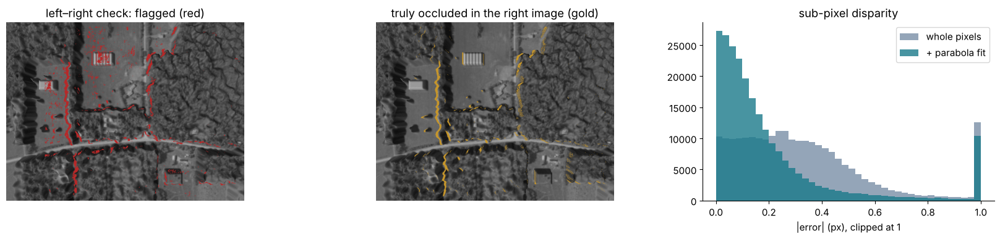

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.0), gridspec_kw={"width_ratios": [1, 1, 0.9]})
ov = np.dstack([L] * 3).astype(np.float32) / 255 * 0.75
ov[f_] = [0.72, 0.16, 0.16]
axes[0].imshow(ov); axes[0].set_title("left–right check: flagged (red)")
ov2 = np.dstack([L] * 3).astype(np.float32) / 255 * 0.75
ov2[o_] = [0.78, 0.59, 0.17]
axes[1].imshow(ov2); axes[1].set_title("truly occluded in the right image (gold)")
for a in axes[:2]: a.axis("off")
bins = np.linspace(0, 1, 41)
axes[2].hist(np.clip(e_int, 0, 1), bins, color=GREY, alpha=0.8, label="whole pixels")
axes[2].hist(np.clip(e_sub, 0, 1), bins, color=TEAL, alpha=0.8, label="+ parabola fit")
axes[2].set_xlabel("|error| (px), clipped at 1"); axes[2].set_title("sub-pixel disparity"); axes[2].legend()
plt.tight_layout(); plt.show()

Occlusions sit on the **left** side of anything tall (the right camera, 40 m east, can't see
past it). The check catches many of them — and also flags plain mistakes, which is just as
useful. Sub-pixel interpolation fits a parabola through the cost at the best disparity and
its two neighbours; it costs nothing and halves the depth error.

---
## 10 · From disparity to heights

$Z = fB/d$ at every pixel, then height $= 250 - Z$ (the left camera looks straight down from
250 m). How tall are the barns? Take the median height on the roof minus the median height
of a ring of ground around it.

In [30]:
Z_SG = F_PX * B / D_SG
H_SG = HF - Z_SG
print(f"{'':16s}{'true':>8s}{'SGBM':>8s}{'SAD 7×7':>10s}   (barn height, m)")
for name, (x, y, w, h, ht) in BARNS.items():
    roof = ROOFS[name]
    X0, Y0 = x * GSD, y * GSD
    near = ((PL[..., 0] > X0 - 10) & (PL[..., 0] < X0 + w * GSD + 10) & (PL[..., 1] > Y0 - 10) &
            (PL[..., 1] < Y0 + h * GSD + 10) & OPEN)                  # open ground within 10 m
    vals = []
    for D in (D_SG, WIN[("SAD", 7)][0]):
        Hm = HF - F_PX * B / D
        vals.append(np.nanmedian(Hm[roof]) - np.nanmedian(Hm[near]))
    print(f"{name:16s}{ht:8.1f}{vals[0]:8.1f}{vals[1]:10.1f}")
ew = np.abs(H_SG - HGT)[EVAL & np.isfinite(H_SG)]
print(f"\nwhole scene, SGBM: height error median {np.median(ew):.2f} m, 90th pct {np.percentile(ew, 90):.2f} m")

                    true    SGBM   SAD 7×7   (barn height, m)
white roof          10.0     9.5      10.8
ribbed roof          8.0     8.0       8.5
textured roof       12.0    11.6      12.1

whole scene, SGBM: height error median 0.54 m, 90th pct 1.57 m


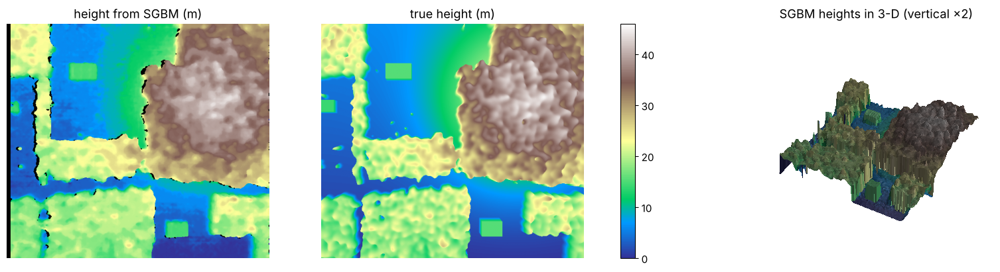

In [31]:
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401  (registers the 3-D projection)
cm = plt.get_cmap("terrain").copy(); cm.set_bad("black")
fig = plt.figure(figsize=(17, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 0.05, 1.5])
for k, (Hm, ttl) in enumerate(((H_SG, "height from SGBM (m)"), (HGT, "true height (m)"))):
    ax = fig.add_subplot(gs[k]); h_ = ax.imshow(Hm[:, DMAX:], cmap=cm, vmin=0, vmax=46)
    ax.set_title(ttl); ax.axis("off")
fig.colorbar(h_, cax=fig.add_subplot(gs[2]))
ax3 = fig.add_subplot(gs[3], projection="3d")
s_ = 4
Hs = cv2.medianBlur(np.nan_to_num(H_SG, nan=0).astype(np.float32), 5)[::s_, DMAX::s_]
img_ = L[::s_, DMAX::s_] / 255.0
cols_ = 0.55 * cm(np.clip(Hs / 46, 0, 1)) + 0.45 * np.dstack([img_] * 3 + [np.ones_like(img_)])
Ys, Xs = np.mgrid[0:Hs.shape[0], 0:Hs.shape[1]] * s_ * 0.5       # metres
ax3.plot_surface(Xs, -Ys, Hs, facecolors=np.clip(cols_, 0, 1), rstride=1, cstride=1, linewidth=0, antialiased=False)
ax3.set_box_aspect((Xs.max(), Ys.max(), 2 * 46)); ax3.view_init(40, -60)
ax3.set_title("SGBM heights in 3-D (vertical ×2)"); ax3.set_axis_off()
plt.subplots_adjust(left=0.01, right=0.99, wspace=0.08); plt.show()

---
## 11 · Real data: the 1958 pair

Back to frames 16046-19 → 16046-20 (AL5, L8, L10). No calibration, no ground truth — but the
geometry is the same. Estimate $F$ with SIFT + MAGSAC, as in section 4.

In [32]:
A0 = cv2.imread("frames/16046-19.jpg", cv2.IMREAD_GRAYSCALE)
B0 = cv2.imread("frames/16046-20.jpg", cv2.IMREAD_GRAYSCALE)
H_REF = np.array([[ 0.98700935, -0.00873884, -390.04915793],     # frame 19 -> frame 20 (AL5, L8, L10)
                  [ 0.00098735,  1.01974419,  -25.81833349],
                  [-0.00000007,  0.00002919,    1.        ]])
ka5, da5 = sift.detectAndCompute(A0, None); kb5, db5 = sift.detectAndCompute(B0, None)
g5 = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(da5, db5, k=2) if m.distance < 0.7 * n.distance]
p19 = np.float64([ka5[m.queryIdx].pt for m in g5]); p20 = np.float64([kb5[m.trainIdx].pt for m in g5])
cv2.setRNGSeed(0)
F58, m58 = cv2.findFundamentalMat(p19, p20, cv2.USAC_MAGSAC, 1.0, 0.9999, 20000); m58 = m58.ravel() > 0
P19, P20 = p19[m58], p20[m58]
e19, e20 = null_vec(F58), null_vec(F58.T)
lines20 = np.c_[P19, np.ones(len(P19))] @ F58.T
tilt = np.degrees(np.arctan(-lines20[:, 0] / lines20[:, 1]))
d58 = epi_dist(F58, P19, P20)
print(f"{len(g5)} matches, {m58.sum()} F-inliers; median distance to the epipolar line {np.median(d58):.2f} px")
print(f"epipole in frame 20 at ({e20[0]:,.0f}, {e20[1]:,.0f}),  in frame 19 at ({e19[0]:,.0f}, {e19[1]:,.0f})")
print(f"epipolar lines in frame 20 are tilted {np.percentile(tilt, 1):+.2f}° .. {np.percentile(tilt, 99):+.2f}° from horizontal")

1232 matches, 1196 F-inliers; median distance to the epipolar line 0.17 px
epipole in frame 20 at (21,789, 276),  in frame 19 at (19,828, 305)
epipolar lines in frame 20 are tilted -1.71° .. +0.67° from horizontal


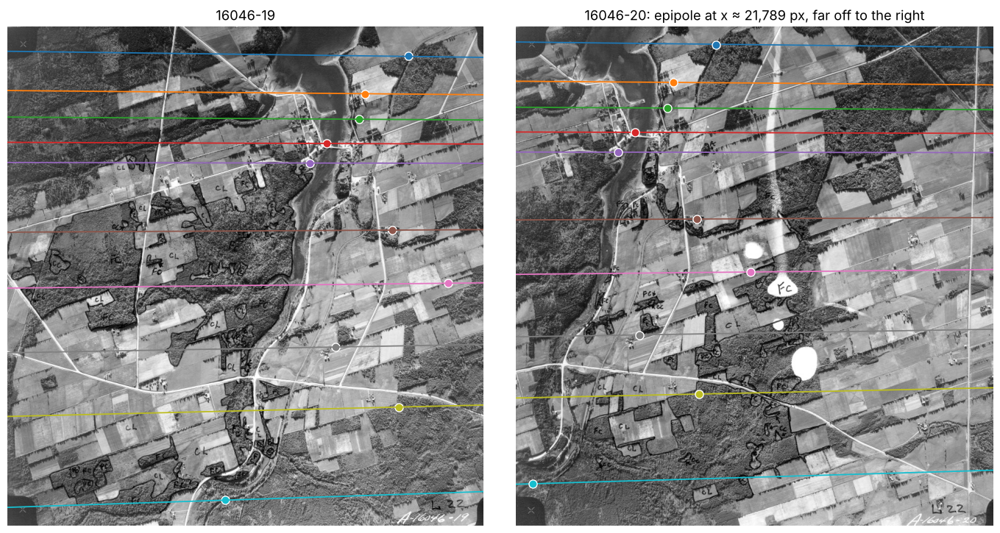

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
axes[0].imshow(A0, cmap="gray"); axes[1].imshow(B0, cmap="gray")
idx = np.argsort(P19[:, 1])[np.linspace(20, len(P19) - 20, 10).astype(int)]
for k, i in enumerate(idx):
    c = plt.cm.tab10(k)
    axes[0].plot(*P19[i], "o", color=c, ms=8, mec="w")
    a, b, c_ = F58 @ np.r_[P19[i], 1]
    xs = np.array([0, B0.shape[1]]); axes[1].plot(xs, -(a * xs + c_) / b, color=c, lw=1.3)
    axes[1].plot(*P20[i], "o", color=c, ms=8, mec="w")
    a, b, c_ = F58.T @ np.r_[P20[i], 1]
    xs = np.array([0, A0.shape[1]]); axes[0].plot(xs, -(a * xs + c_) / b, color=c, lw=1.3)
axes[0].set_title("16046-19"); axes[1].set_title(f"16046-20: epipole at x ≈ {e20[0]:,.0f} px, far off to the right")
for ax, I in zip(axes, (A0, B0)):
    ax.set_xlim(0, I.shape[1]); ax.set_ylim(I.shape[0], 0); ax.axis("off")
plt.tight_layout(); plt.show()

The epipole is about 20 frame-widths to the side: the epipolar lines are almost exactly the
image rows. The plane flew along $x$ and took a vertical photo every few seconds — an aerial
survey is a (nearly) rectified stereo rig with a 400-px baseline. That is why L10's leftover
flow was along $x$, and it is how every topographic map before about 2000 was made: two
overlapping vertical photos under a stereoscope.

### 11.1 — Plane + parallax

$F$ says *where along the line*, not *how far*. As in L10, let the homography remove the
ground plane and measure what is left along $x$: the **parallax** relative to that plane.

In [34]:
par = P20 - cv2.perspectiveTransform(P19[None], H_REF)[0]          # what the plane does not explain
print(f"F-inliers relative to the ground-plane homography (5th..95th pct): x {np.percentile(par[:, 0], 5):+.1f} .. "
      f"{np.percentile(par[:, 0], 95):+.1f} px,  y {np.percentile(par[:, 1], 5):+.1f} .. {np.percentile(par[:, 1], 95):+.1f} px")
print(f"{np.mean(np.linalg.norm(par, axis=1) < 1):.0%} are within 1 px of the plane; "
      f"{np.mean(np.linalg.norm(par, axis=1) < 3):.0%} within 3 px")

hh, ww = B0.shape
Aw = cv2.warpPerspective(A0, H_REF, (ww, hh))
over = cv2.erode((cv2.warpPerspective(np.full_like(A0, 255), H_REF, (ww, hh)) > 0).astype(np.uint8),
                 np.ones((15, 15), np.uint8)) > 0
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
Lw, Rw = clahe.apply(Aw), clahe.apply(B0)
sg58 = cv2.StereoSGBM_create(minDisparity=-8, numDisparities=16, blockSize=5, P1=200, P2=800, uniquenessRatio=5,
                             speckleWindowSize=100, speckleRange=2, disp12MaxDiff=1, mode=cv2.STEREO_SGBM_MODE_HH)
t0 = time.perf_counter(); D58 = sg58.compute(Lw, Rw).astype(np.float32) / 16; t58 = time.perf_counter() - t0
D58[(D58 <= -8) | ~over] = np.nan
q = cv2.perspectiveTransform(P19[None], H_REF)[0].round().astype(int)
q[:, 0] = np.clip(q[:, 0], 0, ww - 1); q[:, 1] = np.clip(q[:, 1], 0, hh - 1)
dd = D58[q[:, 1], q[:, 0]]; okd = np.isfinite(dd)
print(f"SGBM on the warped pair: {1000 * t58:.0f} ms, answers {np.isfinite(D58)[over].mean():.0%} of the overlap")
print(f"dense vs sparse parallax at {okd.sum()} F-inliers: correlation {np.corrcoef(dd[okd], -par[okd, 0])[0, 1]:.2f}, "
      f"median difference {np.median(np.abs(dd[okd] + par[okd, 0])):.2f} px")

F-inliers relative to the ground-plane homography (5th..95th pct): x -2.8 .. +2.8 px,  y -0.7 .. +0.8 px
44% are within 1 px of the plane; 91% within 3 px
SGBM on the warped pair: 120 ms, answers 95% of the overlap
dense vs sparse parallax at 1193 F-inliers: correlation 0.96, median difference 0.22 px


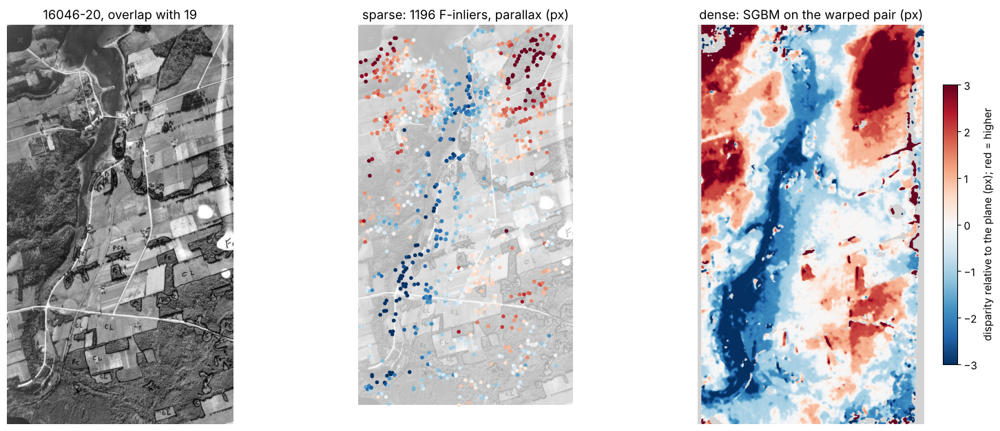

In [35]:
ys_, xs_ = np.nonzero(over)
crop = (slice(ys_.min(), ys_.max() + 1), slice(xs_.min(), xs_.max() + 1))
relief = cv2.medianBlur(np.nan_to_num(D58, nan=0).astype(np.float32), 5)
relief = np.where(np.isfinite(D58), relief, np.nan)
fig, axes = plt.subplots(1, 3, figsize=(16, 6.4))
axes[0].imshow(B0[crop], cmap="gray"); axes[0].set_title("16046-20, overlap with 19")
cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
axes[1].imshow(B0[crop], cmap="gray", alpha=0.35)
sc = axes[1].scatter(P20[:, 0] - xs_.min(), P20[:, 1] - ys_.min(), c=-par[:, 0], cmap="RdBu_r", vmin=-3, vmax=3, s=9)
axes[1].set_title(f"sparse: {len(P20)} F-inliers, parallax (px)")
h_ = axes[2].imshow(relief[crop], cmap=cm, vmin=-3, vmax=3); axes[2].set_title("dense: SGBM on the warped pair (px)")
fig.colorbar(h_, ax=axes[2], shrink=0.7, label="disparity relative to the plane (px); red = higher")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Red is **higher** (it moved further between the photos). The river valley is blue (low); the
woodlots stand out as red blocks above the fields around them — tree canopy, like our
synthetic woodlots. The isolated spikes are the 1958 forester's ink marks, which differ
between the two prints.

**How high?** With the base $b = 403$ px between photo centres and flying height $H_f$,
a point $h$ above the plane shifts by about $\Delta p \approx b\,h / H_f$. We do not know
$H_f$ for this flight. *If* the photos are about 1:15,800 with a 6-inch (152 mm) lens —
typical for the period, but not verified — then $H_f \approx 0.152 \times 15{,}800 \approx 2.4$ km and 1 px of parallax
≈ 6 m of height, so the ±3 px range is roughly ±18 m.

### 11.2 — See it in 3-D

Red–cyan glasses? Red channel = frame 19 warped onto 20 (left eye), green and blue = frame 20
(right eye). The ground plane sits at the screen; woodlots float in front of it.

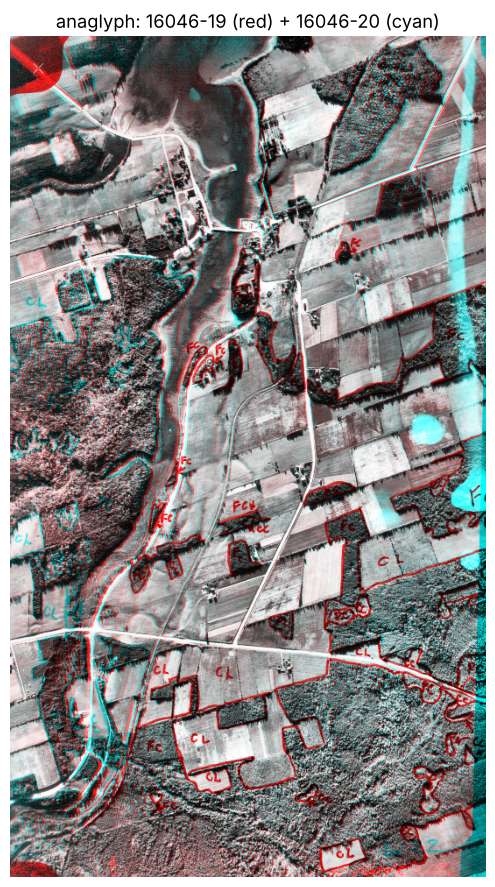

uncalibrated rectification from F alone: |y′ − y| median 0.17 px, disparity -3.1 .. 3.6 px


In [36]:
ana = np.dstack([Lw, Rw, Rw])[crop]
fig, ax = plt.subplots(figsize=(8.5, 9))
ax.imshow(ana); ax.set_title("anaglyph: 16046-19 (red) + 16046-20 (cyan)"); ax.axis("off")
plt.tight_layout(); plt.show()

ok_, H1u, H2u = cv2.stereoRectifyUncalibrated(P19, P20, F58, (ww, hh))
r19 = cv2.perspectiveTransform(P19[None], H1u)[0]; r20 = cv2.perspectiveTransform(P20[None], H2u)[0]
print(f"uncalibrated rectification from F alone: |y′ − y| median {np.median(np.abs(r20[:, 1] - r19[:, 1])):.2f} px, "
      f"disparity {np.percentile(r19[:, 0] - r20[:, 0], 1):.1f} .. {np.percentile(r19[:, 0] - r20[:, 0], 99):.1f} px")

---
## 12 · Pitfalls

### 12.1 — Brightness differences and misalignment
Two cameras rarely have identical exposure (the 1958 prints differ by 13 grey levels, L8),
and calibration drifts. Make the right image 30% brighter, or shift it down by 1–3 rows:

In [37]:
cases = {"unchanged": R, "right ×1.3 + 10": np.clip(R * 1.3 + 10, 0, 255).astype(np.uint8)}
for dy in (1, 2, 3):
    cases[f"right shifted {dy} px down"] = np.roll(R, dy, 0)
PIT = {}
print(f"{'':26s}{'SAD 7×7':>10s}{'ZNCC 7×7':>10s}{'SGBM 5':>9s}   (share of pixels off by > 1 px)")
for name, R2 in cases.items():
    D_sgbm = sgbm().compute(L, R2).astype(np.float32) / 16; D_sgbm[D_sgbm < 64] = np.nan
    vals = [score(wta(*cost_volume(L, R2, 7, "SAD")))[1], score(wta(*cost_volume(L, R2, 7, "ZNCC")))[1], score(D_sgbm)[1]]
    PIT[name] = vals
    print(f"{name:26s}" + "".join(f"{v:10.1%}" for v in vals))

                             SAD 7×7  ZNCC 7×7   SGBM 5   (share of pixels off by > 1 px)


unchanged                       4.3%      8.5%      6.0%


right ×1.3 + 10                95.7%      9.1%     35.9%


right shifted 1 px down        19.3%     23.0%      9.4%


right shifted 2 px down        50.2%     60.0%     21.0%


right shifted 3 px down        70.5%     80.0%     44.1%


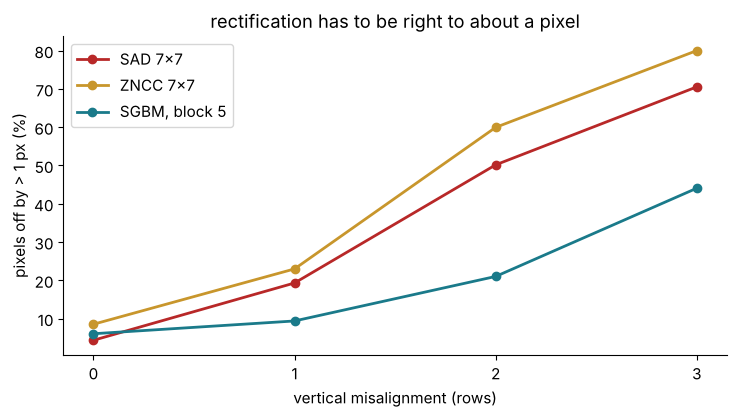

In [38]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
shift_names = ["unchanged"] + [f"right shifted {dy} px down" for dy in (1, 2, 3)]
for k, (lab, col) in enumerate((("SAD 7×7", RED), ("ZNCC 7×7", GOLD), ("SGBM, block 5", TEAL))):
    ax.plot([0, 1, 2, 3], [100 * PIT[n][k] for n in shift_names], "-o", color=col, lw=2, label=lab)
ax.set_xticks([0, 1, 2, 3]); ax.set_xlabel("vertical misalignment (rows)")
ax.set_ylabel("pixels off by > 1 px (%)"); ax.set_title("rectification has to be right to about a pixel")
ax.legend(); plt.tight_layout(); plt.show()

* **Brightness**: SAD compares raw grey levels, so a gain change destroys it; ZNCC subtracts
  the mean and divides by the spread, so it doesn't care. SGBM (Birchfield–Tomasi cost on a
  prefiltered image) is in between. Fix: normalise, or use a zero-mean cost (ZNCC, census).
* **Misalignment**: a 2-row error already ruins most pixels for window matching. Rectify
  carefully, and re-check with a few matches ($|y' - y|$) — section 6.
* **No texture** (white roof), **repetition** (ribbed roof) and **occlusion** (left of tall
  objects): sections 7–9.
* **Depth precision falls with distance squared** ($\delta Z = Z^2\delta d / fB$). Small
  baselines are easy to match but imprecise; large ones are precise but occlude more and
  look more different. Aerial surveys use about 60% overlap as the compromise.
* **Non-Lambertian surfaces** — water glints, shiny roofs — look different from the two
  positions; nothing matches.

---
## 13 · Make your own magic eye — now its own notebook

The magic-eye section has moved to a short notebook of its own, **`L11_MagicEye.ipynb`** (in this
folder; nothing to download):
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L11-Stereo/L11_MagicEye.ipynb)

It covers how to look at one, why a **narrower repeat looks nearer** (the repeat is
*eye spacing − disparity*, so it is the same rule as $Z = fB/d$), making your own, cracking it with
block matching, the second dip from repetition, and why tilting your head (an un-rectified pair)
breaks it.

---
## ✏️ Try at home

Not graded. **A** and **B** are good preparation for Test 2 (Friday).

### A — Depth by hand
A robot's stereo camera has $f = 800$ px and $B = 12$ cm. A box appears at disparity 32 px.
How far away is it? How much does the depth change if the disparity is off by half a pixel?
At what disparity is the box 6 m away, and what is the half-pixel error then?

### B — The epipolar line of a sideways rig
For $R = I$, $t = (1, 0, 0)$, write out $E = [t]_\times$, compute $E\hat x$ for
$\hat x = (0.2, 0.1, 1)$, and show the epipolar line is $\hat y' = 0.1$. Check with NumPy.

### C — Baseline trade-off
Re-render the right camera at $B$ = 10, 20, 40, 80 m. For each, run SGBM (adjust the search
range: the ground is at $fB/250$ px), and plot (i) the median **height** error and (ii) the
share of occluded pixels against $B$.

### D — Your own stereo pair
Take two phone photos of a desk scene, moving the phone ~10 cm sideways between them.
Estimate $F$ (SIFT + MAGSAC), rectify with `cv2.stereoRectifyUncalibrated`, and run SGBM.
What goes wrong, and which pitfall in section 12 is it?

### E — Crack a classmate's magic eye
In **`L11_MagicEye.ipynb`** (section 8, task A): hide your initials, send a classmate the **image only**, and crack theirs. What search range did you need? What happens if your range includes two repeats?

---
## 🔎 Explore further (optional)

* **[Middlebury stereo benchmark](https://vision.middlebury.edu/stereo/)** — Scharstein &
  Szeliski's (2002) evaluation with ground-truth disparity (from structured light); the
  "bad > 1 px" score we used is theirs.
* **[KITTI stereo](https://www.cvlibs.net/datasets/kitti/eval_scene_flow.php?benchmark=stereo)** —
  driving scenes with LiDAR ground truth.
* **Learned stereo** — RAFT-Stereo (Lipson et al. 2021) builds the same cost volume from
  learned features and refines it iteratively, like L10's RAFT. L18 (Nov 30) returns to depth:
  multi-view stereo, structure from motion and networks that estimate depth from a single image.